# Reproducing the numerical study

*On the (non-)coincidence of the serial and Shapley solutions in multi-server queueing and scheduling
problems* (Banerjee and Trudeau), Section 6.

**This notebook already shows its results.** Nothing needs to be run to read it. To re-run it, choose
**Run > Run All Cells**; with the settings below that takes about two minutes. The folder
`launchers/` opens this notebook on Windows, macOS and Linux with nothing else installed, and
the README has a link that opens it in Google Colab.

| Part | What it does |
| --- | --- |
| 1 | Sets up, and shows the versions in use |
| 2 | Works through the paper's running example |
| 3 | Checks the fast Shapley calculation against the definition |
| 4 | Recomputes a sample of problems and compares them with the saved study |
| 5 | Rebuilds the numbers of Section 6, Table 3 and Figure 1, and compares them with the paper |
| 6 | Shows the distance from the bound of Proposition 2 |
| 7 | Runs the automated tests |
| 8 | Optional: re-runs all 78,480 problems |

In [1]:
# Settings
RUN_TESTS = True          # part 7: about a minute
RUN_FULL_GRID = False     # part 8: about 20 minutes on a laptop, over half an hour on Colab; False uses the saved results


## 1. Setup

In [2]:
import hashlib, json, os, platform, shutil, subprocess, sys
from fractions import Fraction
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPOSITORY = "https://github.com/christiantrudeau/coincidence-Shapley-serial"

def find_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "src" / "shapdp.py").exists():
            return base
    return None

if find_root() is None and IN_COLAB:
    subprocess.run(["git", "clone", "--depth", "1", REPOSITORY], check=True)
    os.chdir("coincidence-Shapley-serial")

ROOT = find_root()
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository folder.")
SRC, TESTS, DATA, RESULTS = ROOT / "src", ROOT / "tests", ROOT / "data", ROOT / "results"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(SRC))
sys.path.insert(0, str(TESTS))

import numpy as np, pandas as pd, matplotlib
from IPython.display import Image, Markdown, display
from run_grid import one, NS, KS, RHOS, DISTS
from shapdp import shapley_opt_div, serial_div, grand_cost, completion_times, brute_shapley
from shapdp_exact import shapley_opt_div_exact, serial_div_exact
from compare_results import compare_grid

print("Python    ", platform.python_version())
print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", matplotlib.__version__)
print("Machine   ", platform.processor() or platform.machine(), "|", os.cpu_count(), "logical processors |", platform.system())


Python     3.14.7
numpy      2.5.3
pandas     3.0.6
matplotlib 3.11.2
Machine    Intel64 Family 6 Model 170 Stepping 4, GenuineIntel | 22 logical processors | Windows


## 2. The running example

Three groups share $k=2$ servers, with job lengths $l=(2,3,6)$ and $w_0=1$. With divisible jobs, the
shortest jobs go first, and a group's waiting cost runs until its last unit is done.

In [3]:
l, k = [2, 3, 6], 2
print("Completion periods:", completion_times(l, k).astype(int).tolist())
print("Total cost C(N):   ", int(grand_cost(l, k)))

sh = [str(x) for x in shapley_opt_div_exact(l, k)]
se = [str(x) for x in serial_div_exact(l, k)]
pd.DataFrame({"Shapley value": sh, "Serial rule": se}, index=["Group 1", "Group 2", "Group 3"])

Completion periods: [1, 3, 6]
Total cost C(N):    10


,Shapley value,Serial rule
Group 1,2,2
Group 2,7/2,3
Group 3,9/2,5


The two rules differ for groups 2 and 3, as in Table 2 of the paper. The gap comes from rounding: a job
that ends part-way through a period leaves a slot that the next job uses.

## 3. The fast calculation against the definition

`shapley_opt_div` is the dynamic program of Section 6, in $O(n^3k)$ operations. `brute_shapley` applies
the definition over all $2^n$ coalitions, which is only possible for small $n$.

In [4]:
import random
rng = random.Random(0)
worst = 0.0
for _ in range(200):
    n = rng.randint(1, 10)
    k_ = rng.choice([1, 2, 3, 4, 5, 8, 16])
    l_ = [rng.randint(1, 3 * k_ + 2) for _ in range(n)]
    worst = max(worst, float(np.max(np.abs(shapley_opt_div(l_, k_) - brute_shapley(l_, k_)))))
print(f"Largest difference over 200 random problems: {worst:.1e}")

Largest difference over 200 random problems: 5.0e-14


## 4. A sample recomputed from scratch

Every problem has its own fixed seed. This part recomputes 216 problems and compares every measure
with the saved study. If this machine's software changed the random draws, it would show here.

In [5]:
grid = pd.read_csv(DATA / "grid_results.csv")
print(f"Saved study: {len(grid):,} problems")

tasks = [(n, k_, r, d, 0) for n in (5, 10, 20) for k_ in KS for r in RHOS for d in DISTS]
fresh = pd.DataFrame([one(t) for t in tasks])
keys = ["n", "k", "rho_target", "dist", "rep"]
both = fresh.merge(grid, on=keys, suffixes=("", "_saved"))
cols = [c for c in fresh.columns if c not in keys and c != "any_diff"]
worst = max(float((both[c] - both[c + "_saved"]).abs().max()) for c in cols)
print(f"Problems compared: {len(both)} of {len(tasks)}")
print(f"Largest difference in any measure: {worst:.1e}")
print("Same rules-differ flag in all:", bool((both.any_diff == both.any_diff_saved).all()))

Saved study: 78,480 problems


Problems compared: 216 of 216
Largest difference in any measure: 1.0e-16
Same rules-differ flag in all: True


## 5. Section 6, Table 3 and Figure 1

`summarize.py` and `make_fig.py` run here on the study's data, and every value is
compared with the outputs saved for the paper.

In [6]:
def flat(d, prefix=""):
    out = {}
    for key, value in d.items():
        if isinstance(value, dict):
            out.update(flat(value, f"{prefix}{key} / "))
        else:
            out[prefix + key] = value
    return out

csv_here = OUT / "grid_results.csv"
if not csv_here.exists():
    shutil.copy(DATA / "grid_results.csv", csv_here)
for script in ("summarize.py", "make_fig.py"):
    subprocess.run([sys.executable, str(SRC / script)], cwd=OUT, check=True, capture_output=True)

new = flat(json.loads((OUT / "summary.json").read_text()))
old = flat(json.loads((RESULTS / "summary.json").read_text()))
table = pd.DataFrame({"Recomputed": pd.Series(new), "Paper": pd.Series(old)})
table["Match"] = table.Recomputed == table.Paper
print(f"{int(table.Match.sum())} of {len(table)} values match the paper")
table.head(12)

73 of 73 values match the paper


,Recomputed,Paper,Match
instances,78480.0,78480.0,True
differ_all_pct,96.5,96.5,True
differ_n_ge_20_min_cell_pct,98.1,98.1,True
coincide_share_with_n_le_10_pct,95.6,95.6,True
median_gmax_n20_by_rho_pct / 0.5,7.4,7.4,True
median_gmax_n20_by_rho_pct / 1.0,5.5,5.5,True
median_gmax_n20_by_rho_pct / 2.0,3.6,3.6,True
median_gmax_n20_by_rho_pct / 5.0,1.7,1.7,True
median_gmax_n20_by_rho_pct / 10.0,0.9,0.9,True
median_gmax_n20_by_rho_pct / 20.0,0.4,0.4,True


In [7]:
rows = [line.replace("\\\\", "").split("&") for line in (OUT / "table3_rows.tex").read_text().strip().splitlines()]
t3 = pd.DataFrame([[c.strip() for c in r] for r in rows], columns=["Mean length / k", "n=5", "n=10", "n=20", "n=50", "n=100", "Max"])
same = (OUT / "table3_rows.tex").read_text().split() == (RESULTS / "table3_rows.tex").read_text().split()
print("Table 3, median (95th percentile) of the largest gap, % of the average share. Identical to the paper:", same)
t3

Table 3, median (95th percentile) of the largest gap, % of the average share. Identical to the paper: True


,Mean length / k,n=5,n=10,n=20,n=50,n=100,Max
0,0.5,14.3 (43.2),12.5 (33.3),7.4 (22.2),3.4 (10.7),1.9 (4.8),77.8
1,1,13.5 (31.2),9.4 (22.3),5.5 (13.7),2.5 (6.1),1.4 (2.8),66.7
2,2,9.2 (25.0),6.3 (14.8),3.6 (8.0),1.6 (3.5),0.8 (1.8),62.5
3,5,4.2 (13.9),2.9 (8.2),1.7 (4.3),0.8 (1.6),0.4 (0.7),52.8
4,10,2.1 (8.0),1.5 (4.3),0.9 (2.3),0.4 (0.9),0.2 (0.5),30.0
5,20,1.1 (4.2),0.8 (2.3),0.4 (1.2),0.2 (0.5),0.1 (0.2),14.2


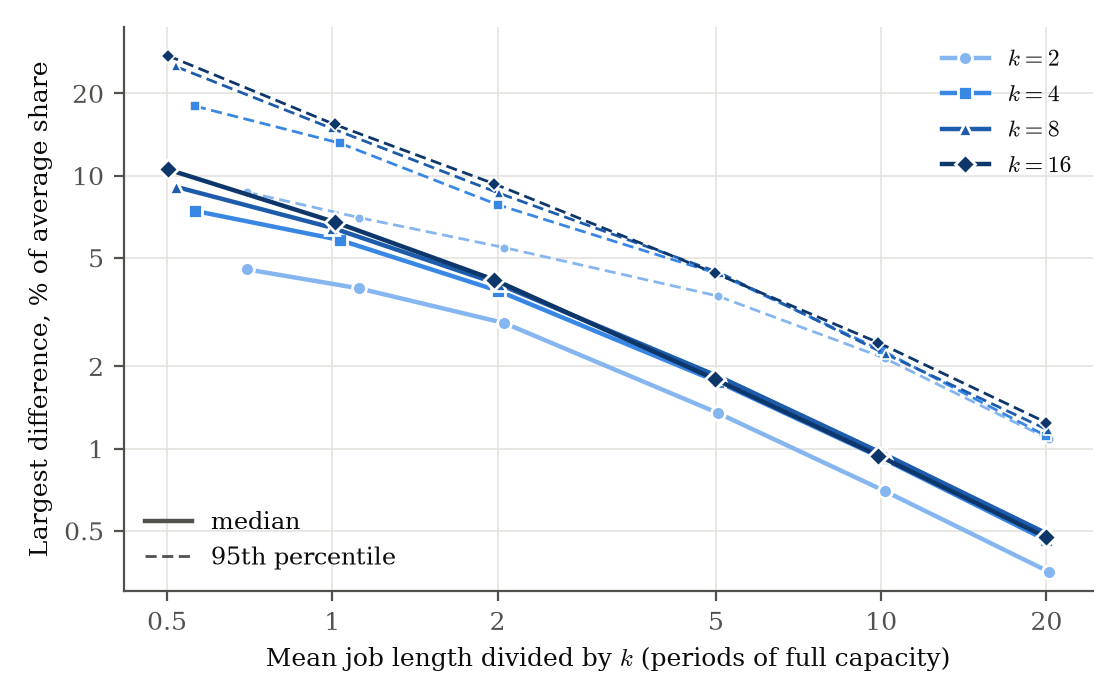

In [8]:
display(Image(filename=str(OUT / "fig_gap.png"), width=620))

## 6. Distance from the bound of Proposition 2

The bound is $|Sh_i-Ser_i|\le w_0\,n(k-1)/k$. The largest gap found, as a share of the bound, stays
at or below one half, in the grid and in the hill-climbing searches.

In [9]:
g = grid.assign(share=2 * grid.g_bound).groupby("n").share.max().round(3)
adv = json.loads((RESULTS / "adv2_results.json").read_text())
print("Largest gap / bound in the grid, by n:", g.to_dict())
print("Largest gap / bound in the search, n up to 16:", round(max(r["gap_over_bound"] for r in adv), 3))
print("Bound violations in the grid:", int((2 * grid.g_bound > 1 + 1e-9).sum()))

Largest gap / bound in the grid, by n: {5: 0.48, 10: 0.5, 20: 0.26, 50: 0.104, 100: 0.051}
Largest gap / bound in the search, n up to 16: 0.5
Bound violations in the grid: 0


## 7. Automated tests

In [10]:
if RUN_TESTS:
    done = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests"],
                          cwd=ROOT, capture_output=True, text=True)
    print(done.stderr[-300:])
else:
    print("Skipped: set RUN_TESTS = True at the top.")

.............
----------------------------------------------------------------------
Ran 13 tests in 146.192s

OK



## 8. Optional: all 78,480 problems

Set `RUN_FULL_GRID = True` at the top. The new file is compared with the saved one, value by value
and byte by byte. Bytes can differ across machines through floating-point noise in the last digits;
the designs, the flags and the values reported in the paper do not.

This part takes about 20 minutes on a laptop and over half an hour on Google Colab, and it prints
nothing until it ends. On Colab, keep the tab open; it is best run on your own computer.

In [11]:
if RUN_FULL_GRID:
    (OUT / "grid_results.csv").unlink(missing_ok=True)
    subprocess.run([sys.executable, str(SRC / "run_grid.py")], cwd=OUT, check=True)
    problems, worst, equal, same_bytes = compare_grid(OUT / "grid_results.csv")
    print(f"Problems: {problems:,}. Largest difference: {worst:.1e}. Designs and flags equal: {equal}. Same bytes: {same_bytes}.")
else:
    print("Skipped: this notebook used the saved results.")


Skipped: this notebook used the saved results.
